# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: logistic_regression
Test: (36, 13)


## 2. Evaluación final

Accuracy test : 0.9722
F1 macro test : 0.9710

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



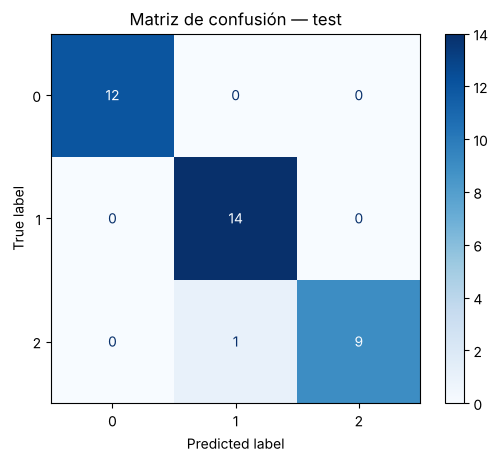

Accuracy CV del campeón: 0.9791
Errores en test: 1 de 36


In [4]:
y_pred = model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy test : {test_accuracy:.4f}")
print(f"F1 macro test : {test_f1_macro:.4f}")
print()
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matriz de confusión — test")
plt.show()

print("Accuracy CV del campeón:", round(training_metadata["cv_accuracy"], 4))
print("Errores en test:", int((y_test.values != y_pred).sum()), "de", len(y_test))

**Análisis:**

> **Coherencia con CV:** sí. La validación cruzada daba un accuracy de ≈ 0.979 y en test salió 0.972 (35 de 36 aciertos), con un F1 macro de 0.971. La diferencia es de menos de un punto, que con solo 36 muestras corresponde a una predicción más o menos.
>
> **Clases confundidas:** el único error fue una muestra de la **clase 2 que el modelo predijo como clase 1** (recall de la clase 2 = 0.90, precisión de la clase 1 = 0.93). La clase 0 se clasificó perfectamente (precisión y recall = 1.0). Tiene sentido con el EDA: las clases 1 y 2 son las más parecidas en varias variables como `proline` y `alcohol`, y lo que más las separa es `color_intensity` y `flavanoids`.
>
> **Sobreajuste:** no hay evidencia fuerte. El modelo tiene 1.0 de accuracy en train (CV), 0.979 en validación y 0.972 en test, es decir, una brecha pequeña y estable. Eso sí, con un test tan pequeño un solo error mueve el accuracy 2.8 puntos porcentuales, así que no se pueden sacar conclusiones finas.

## 3. Función de inferencia

In [5]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    missing = [c for c in feature_columns if c not in records.columns]
    if missing:
        raise ValueError(f"Faltan columnas requeridas: {missing}")

    X = records[feature_columns].copy()

    preds = model.predict(X)
    probas = model.predict_proba(X)

    out = pd.DataFrame(index=records.index)
    out["prediction"] = preds
    for k, cls in enumerate(model.classes_):
        out[f"proba_class_{cls}"] = probas[:, k]
    return out

## 4. Predicción por lotes

In [6]:
new_records = X_test.iloc[:5].copy()

batch_predictions = predict(new_records)
batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
batch_predictions.round(3)

try:
    predict(new_records.drop(columns=["proline"]))
except ValueError as e:
    print("Error esperado ->", e)

Error esperado -> Faltan columnas requeridas: ['proline']


## 5. Reporte final

In [7]:
test_metrics = {
    "model": training_metadata["champion"],
    "accuracy": float(test_accuracy),
    "f1_macro": float(test_f1_macro),
}
(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2), encoding="utf-8"
)
test_metrics

{'model': 'logistic_regression',
 'accuracy': 0.9722222222222222,
 'f1_macro': 0.9709618874773139}

In [8]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | Regresión logística (C = 1) con StandardScaler |
| Accuracy CV | 0.979 (desv. 0.028) |
| Accuracy test | 0.972 (35/36) |
| F1 macro test | 0.971 |
| Clases más confundidas | Clase 2 predicha como clase 1 (1 caso) |
| Principal limitación | Dataset pequeño: test de solo 36 muestras, un error cambia el accuracy casi 3 puntos |

## Checklist

- [x] Evalué únicamente el modelo campeón.
- [x] No reajusté hiperparámetros después de observar test.
- [x] Implementé validación básica del esquema de entrada.
- [x] Generé predicciones por lotes.
- [x] Guardé las métricas finales.

---
### Declaración de uso de IA generativa

Herramienta: Claude (Anthropic). Propósito: asistencia en programación (evaluación, función `predict` con validación de esquema, guardado de resultados) y borrador del análisis y del resumen ejecutivo, que contrasté con las métricas obtenidas en el test.